# Etapa 2 — Análise Exploratória de Dados

Entrada: os CSVs que a Etapa 1 gravou em `../data/raw/`.
Saída: uma tabela horária limpa em `../data/processed/dataset.csv`, mais os
gráficos e as conclusões que sustentam o que você vai afirmar.

As seções abaixo são um roteiro, não uma receita. Responda as perguntas de
cada uma com código e, no fim, em texto. Acrescente seções se quiser.

In [16]:
from pathlib import Path

DIR_RAW = Path("..") / "data" / "raw"
DIR_PROC = Path("..") / "data" / "processed"
DIR_PROC.mkdir(parents=True, exist_ok=True)

# TODO: imports (pandas, matplotlib, seaborn, ...)

In [44]:
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import datetime

## 1. Carregar os CSVs

Leia os quatro arquivos de `../data/raw/`.

- Quantas linhas tem cada um? O número faz sentido para o período coletado?
- Os tipos vieram certos, ou datas e números chegaram como texto?
- Há colunas vazias, ou linhas duplicadas?

*Resposta:*

Primeiro, eu li e guardei os cvs puros em DataFrames do pandas:

In [18]:
mares_2026 = pd.DataFrame(pd.read_csv("/home/laura/Documents/faculdade/trilha/TRILHA2026/miniprojeto2/data/raw/mares_2026.csv"))
maresprev = pd.read_csv("/home/laura/Documents/faculdade/trilha/TRILHA2026/miniprojeto2/data/raw/mares_previsao.csv")
ondas = pd.read_csv("/home/laura/Documents/faculdade/trilha/TRILHA2026/miniprojeto2/data/raw/ondas.csv")
vento = pd.read_csv("/home/laura/Documents/faculdade/trilha/TRILHA2026/miniprojeto2/data/raw/vento.csv")

- Quantas linhas? O número faz sentido?
= Enquanto a primeira tem 1000+ linhas, o resto tem entre 100 a 200 linhas. Faz sentido isso acontecer, já que eu peguei a informação de todo um ano para "mares_2025", enquanto, para os outros, eu usei os dados de, em torno, sete dias (para somente usar "get" e "post", sem outra API).

In [19]:
print(len(mares_2026))
print(len(maresprev))
print(len(ondas))
print(len(vento))

1411
116
168
168


- Os tipos estão certos?
= Alguns sim, enquanto outros não. Ainda há muitos tipos numéricos classificados como string, de acordo com os dados e com o dtypes.

In [20]:
print(mares_2026.dtypes)
print(maresprev.dtypes)
print(ondas.dtypes)
print(vento.dtypes)

data_hora          str
altura_m       float64
nascer_sol         str
por_sol            str
coeficiente      int64
atividade          str
tipo               str
dtype: object
data_hora          str
altura_m       float64
nascer_sol         str
por_sol            str
coeficiente      int64
atividade          str
tipo               str
dtype: object
data_hora                  str
onda_altura_m          float64
swell_altura_m         float64
swell_direcao_graus    float64
swell_periodo_s        float64
dtype: object
data_hora                  str
vento_kmh              float64
rajada_kmh             float64
vento_direcao_graus    float64
vento_direcao              str
dtype: object


- Há colunas vazias ou linhas duplicadas?
= Não há nenhum dos dois. O raciocínio segue nos comentários do código abaixo.

In [21]:
## Como eu fiz primeiro a pergunta de linhas duplicadas, pesquisei o comando de dropar linhas 
## vazias e fiz a mesma subtração
print(len(mares_2026) - len(mares_2026.dropna()))
print(len(maresprev) - len(maresprev.dropna()))
print(len(ondas) - len(ondas.dropna()))
print(len(vento) - len(vento.dropna()))

## Teste de linhas duplicadas: pesquisei ideias de comandos no pandas para fazer a contagem e 
## decidi seguir um post no StackOverflow.
print(len(mares_2026) - len(mares_2026.drop_duplicates(subset=None, keep='first')))
print(len(maresprev) - len(maresprev.drop_duplicates(subset=None, keep='first')))
print(len(ondas) - len(ondas.drop_duplicates(subset=None, keep='first')))
print(len(vento) - len(vento.drop_duplicates(subset=None, keep='first')))

0
0
0
0
0
0
0
0


## 2. Limpeza

Deixe cada tabela num estado em que dá para confiar.

- Datas e horas: viram `datetime`? Vale montar uma coluna única de data + hora?
- Decimais: o site usa vírgula. Isso já foi resolvido na Etapa 1 ou sobrou aqui?
- O que fazer com nulos: descartar a linha, preencher, ou manter e documentar?
- Duplicatas: existem? De onde vieram?

- Data e hora vieram juntas, em string. Aqui embaixo, eu as separei e coloquei em datetime.

In [22]:
#separação e tipo datetime em mares_2025
mares_2026['data'] = mares_2026['data_hora'].str[:10].astype('datetime64[ns]')
mares_2026['hora'] = mares_2026['data_hora'].str[11:].astype('datetime64[ns]')

# separação e tipo datetime em maresprev
maresprev['data'] = maresprev['data_hora'].str[:10].astype('datetime64[ns]')
maresprev['hora'] = maresprev['data_hora'].str[11:].astype('datetime64[ns]')

# separação e tipo datetime em ondas
ondas['data'] = ondas['data_hora'].str[:10].astype('datetime64[ns]')
ondas['hora'] = ondas['data_hora'].str[11:0].astype('datetime64[ns]')

# separação e tipo datetime em vento
vento['data'] = vento['data_hora'].str[:10].astype('datetime64[ns]')
vento['hora'] = vento['data_hora'].str[11:].astype('datetime64[ns]')

- A parte das vírgulas já está resolvida: os próprios csvs vêm com pontos em seus decimais.

- Os nulos, na parte anterior, foram descartados, para não dar pesos iguais a dados, em informação, diferentes
(por exemplo, um dia com dados completos acaba com a mesma importância de um dia com dados incompletos, de modo que 
um dia poderia afetar somente algumas colunas e outras não - algo que, para atividade, vou considerar inválido).

- Como na parte anterior, não foram achadas duplicatas.

## 3. Explorar cada tabela separadamente

Antes de juntar, entenda cada fonte.

**Marés** — como a altura se distribui entre marés altas e baixas? O
coeficiente varia ao longo do ano com algum padrão? Ele tem relação com a
fase da lua?

**Ondas** — qual a faixa de altura na janela coletada? Há padrão por hora do
dia, ou a variação é só por dia?

**Vento** — quais horas são mais calmas? A direção predominante muda ao longo
do dia? (Vento da terra para o mar e vento do mar para a terra fazem coisas
opostas com a onda.)

Um gráfico por pergunta. Escreva o que você leu nele.

*Resposta:*

1. Para marés:
- Como a onda se distribui entre marés?
= Elas mudam de altura conforme a maré alta / baixa.

- O coeficiente tem padrão?
= Ele segue, em padrão de onda, a altura das marés mais altas de cada dia, sem descidas bruscas.

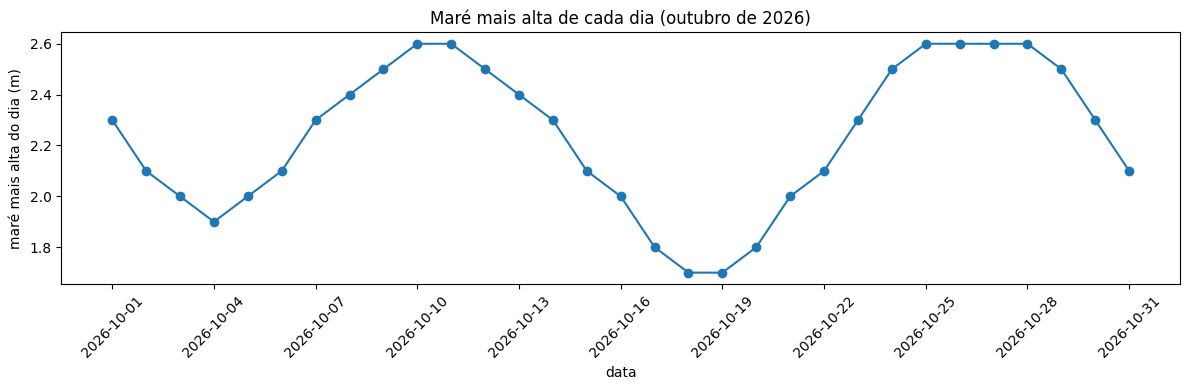

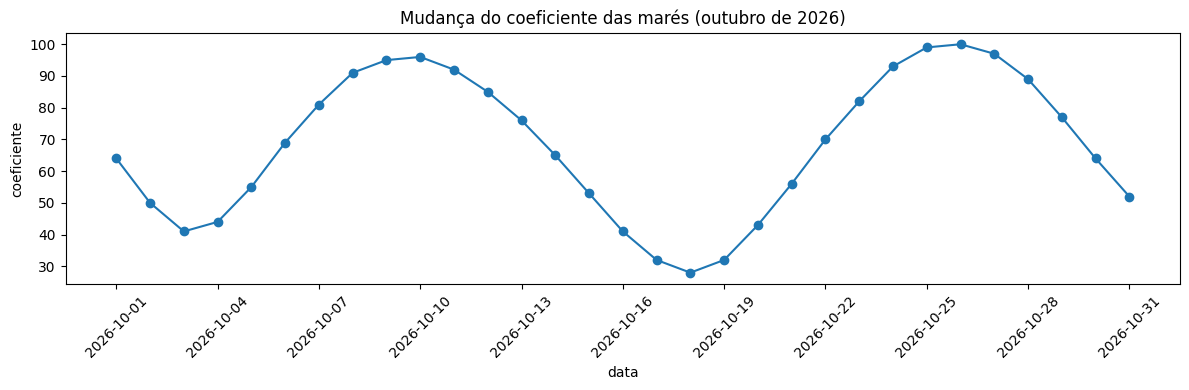

In [23]:
# Gráfico de altura por dia
mes = mares_2026[mares_2026["data"].dt.month==10]
maxima = mes.groupby("data")["altura_m"].max()

plt.figure(figsize=(12, 4))
plt.plot(maxima.index, maxima.values, marker="o")
plt.xlabel("data")
plt.ylabel("maré mais alta do dia (m)")
plt.title("Maré mais alta de cada dia (outubro de 2026)")
plt.xticks(maxima.index[::3], rotation=45)
plt.tight_layout()
plt.show()

# Gráfico de coeficiente
mes = mares_2026[mares_2026["data"].dt.month==10]
coef = mes.groupby(mes["data"].dt.date)["coeficiente"].first()

plt.figure(figsize=(12, 4))
plt.plot(coef.index, coef.values, marker="o")
plt.xlabel("data")
plt.ylabel("coeficiente")
plt.title("Mudança do coeficiente das marés (outubro de 2026)")
plt.xticks(maxima.index[::3], rotation=45)
plt.tight_layout()
plt.show()

2. Para ondas:
- Qual a faixa de altura?
= O intervalo da faixa de altura muda por dia, mas, em geral, esse intervalo tem valor mínimo de 0.5 metros e valor máximo de 1.1 metro.

- Há padrão por hora, ou só por dia?
= Há um menor padrão por hora, em que a altura não costuma ficar muito elevada por longos períodos de tempo, e, sempre que eleva, ela não costuma parar por muito tempo antes de atingir seu valor de ápice.

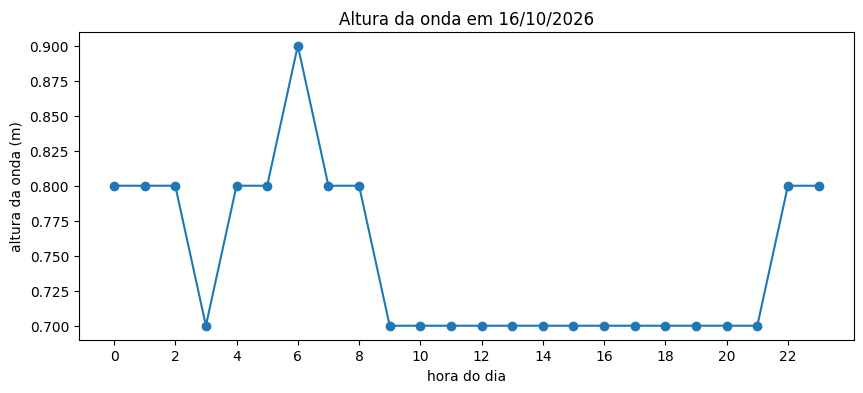

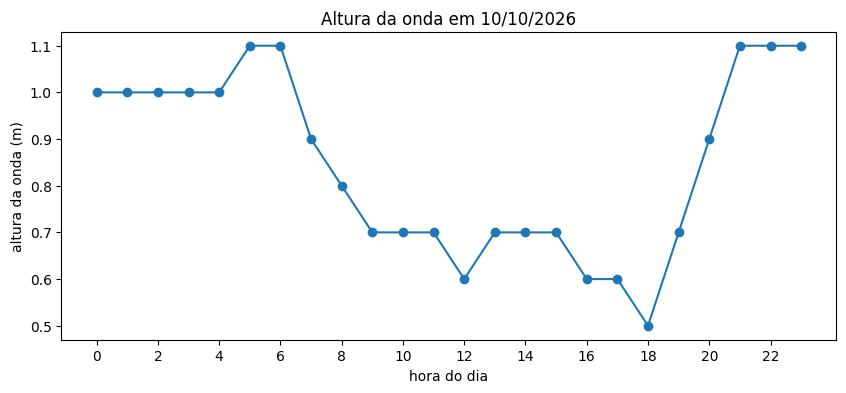

In [24]:
#Gráfico do dia 16
dia = ondas[ondas["data"] == pd.to_datetime("2026-10-16")]

plt.figure(figsize=(10, 4))
plt.plot(range(24), dia["onda_altura_m"].values, marker="o")
plt.xlabel("hora do dia")
plt.ylabel("altura da onda (m)")
plt.title("Altura da onda em 16/10/2026")
plt.xticks(range(0, 24, 2))
plt.show()

# Gráfico do dia 10
dia = ondas[ondas["data"] == pd.to_datetime("2026-10-10")]

plt.figure(figsize=(10, 4))
plt.plot(range(24), dia["onda_altura_m"].values, marker="o")
plt.xlabel("hora do dia")
plt.ylabel("altura da onda (m)")
plt.title("Altura da onda em 10/10/2026")
plt.xticks(range(0, 24, 2))
plt.show()

3. Para vento:
- Quais horas são mais calmas? 
= Mais perto da noite, entre 18h e 22h.

- A direção predominante muda ao longo do dia? 
= Ela sempre muda entre leste-sudeste (ESE), sudeste (SE) e leste (E).

24 0


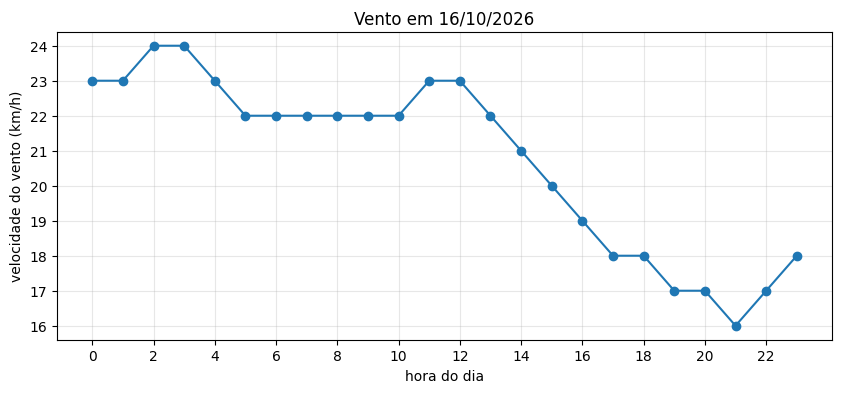

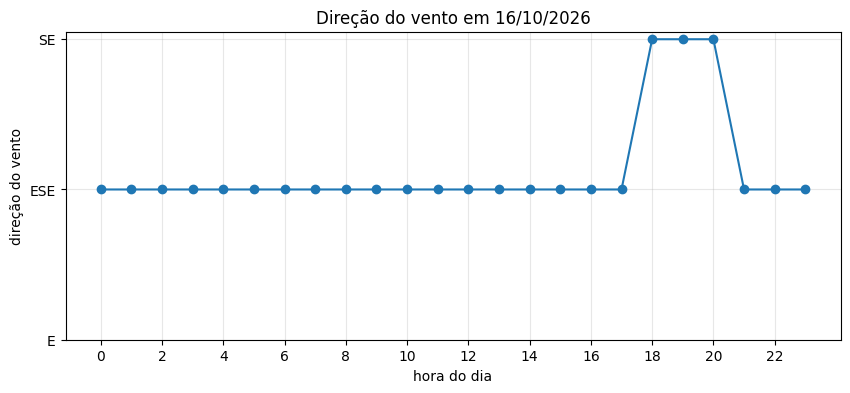

In [25]:
dia = vento[vento["data"] == "2026-10-16"]   
print(len(dia), dia["hora"].isna().sum())

plt.figure(figsize=(10, 4))
plt.plot(dia["hora"].dt.hour, dia["vento_kmh"], marker="o")
plt.xlabel("hora do dia")
plt.ylabel("velocidade do vento (km/h)")
plt.title("Vento em 16/10/2026")
plt.xticks(range(0, 24, 2))
plt.grid(alpha=0.3)
plt.show()

rosa = ["E", "ESE", "SE"]
pos = dia["vento_direcao"].str.strip().map({d: i for i, d in enumerate(rosa)})

plt.figure(figsize=(10, 4))
plt.plot(dia["hora"].dt.hour, pos, marker="o")
plt.xlabel("hora do dia")
plt.ylabel("direção do vento")
plt.title("Direção do vento em 16/10/2026")
plt.xticks(range(0, 24, 2))
plt.yticks(range(len(rosa)), rosa)
plt.grid(alpha=0.3)
plt.show()

## 4. Juntar as tabelas

Esta é a parte difícil, e ela tem mais de uma resposta certa.

As granularidades não batem: onda e vento são leituras horárias; maré são ~4
eventos por dia (os instantes de máxima e mínima). Para ter uma linha por hora
com as três informações você precisa decidir:

- Como levar a maré para a grade horária? Interpolar entre eventos? Repetir o
  último valor? Guardar apenas se a maré está subindo ou descendo? O que cada
  escolha assume sobre a curva real da maré — e onde essa suposição erra?
- Qual o tipo de junção? A previsão de onda e a de vento cobrem exatamente as
  mesmas horas? Se não, você mantém as horas incompletas ou corta?
- Que variáveis derivadas de tempo ajudam a responder a pergunta do projeto
  (dia da semana, período do dia, ...)?

Justifique as escolhas em markdown. Elas são a base das duas próximas etapas.

*Respostas:*

- Como levar para a grade horária?
= Os eventos foram interpolados. Os resultados foram aproximados entre si, então, nenhum deles será exato. Independente da escolha de maré para grade, parte da informação sobre as marés seria perdida, então, a suposição erra em suas aproximações.

In [ ]:
m = pd.read_csv("/home/laura/Documents/faculdade/trilha/TRILHA2026/miniprojeto2/data/raw/mares_2026.csv")
m["t"] = pd.to_datetime(m["data_hora"])
m = m.drop_duplicates("t").sort_values("t").set_index("t")

grade = pd.date_range(m.index.min().floor("D"), m.index.max().ceil("D"), freq="h")
idx = m.index.union(grade)

alt = m["altura_m"].reindex(idx).interpolate(method="time")
ev = pd.Series(m.index, index=m.index).reindex(idx)
buraco = ev.bfill() - ev.ffill()
alt = alt.where(buraco <= pd.Timedelta(hours=8)).reindex(grade)

mare_h = pd.DataFrame({"data": grade.normalize(), "hora": grade.hour,
                       "mare_m": alt.values})
mare_h["mare_subindo"] = mare_h["mare_m"].diff().shift(-1) > 0

m["data"] = m.index.normalize()
dia = m.drop_duplicates("data")[["data", "coeficiente", "atividade"]]

- Qual o tipo de junção? Cobrem as mesmas horas? Que fazer?
= A junção foi em merge. Algumas horas são iguais, ou seja, estão em todos os csvs para a integração. Somente essas horas estão no resultado final, ou seja, as outras horas foram cortadas.

In [ ]:
def padroniza(df):
    df = df.copy()
    df["data"] = pd.to_datetime(df["data"]).dt.normalize()
    df["hora"] = df["hora"].dt.hour
    return df

ondas["hora"] = ondas.groupby("data").cumcount()
print(ondas.groupby("data").size())     
print(ondas[["data", "hora", "onda_altura_m"]].head(3))

o = ondas.copy()
o["data"] = pd.to_datetime(o["data"]).dt.normalize()
v = padroniza(vento)

dataset = (mare_h.merge(dia, on="data", how="left")
                 .merge(o, on=["data", "hora"], how="inner")
                 .merge(v, on=["data", "hora"], how="inner")
                 .dropna()
                 .reset_index(drop=True))

print(dataset.shape)
print(dataset["data"].min(), dataset["data"].max())
print(dataset.dtypes)

- Que variáveis temporais ajudam na resposta?
= Como ondas.csv e vento.csv só tem um mês de informação, acho melhor usar o tempo geral por mês, com comparação de dia e de horário, ou seja, dias da semana e horários cruzados.

## 5. Visualizações voltadas à pergunta

Agora com a tabela junta: quando as condições coincidem?

- As horas de onda maior são as mesmas de vento mais fraco, ou elas se
  desencontram?
- Existe relação visível entre altura da maré e altura da onda?
- Quais dias e horas da janela se destacam?

Prefira poucos gráficos legíveis a muitos gráficos.

*Respostas:*

- As horas de onda maior são as mesmas...?
= As subidas e as decidas de altura / velocidade costumam se encontrar, mas em níveis diferentes (uma descida brusca em um dado não significa uma descida brusca em outro).

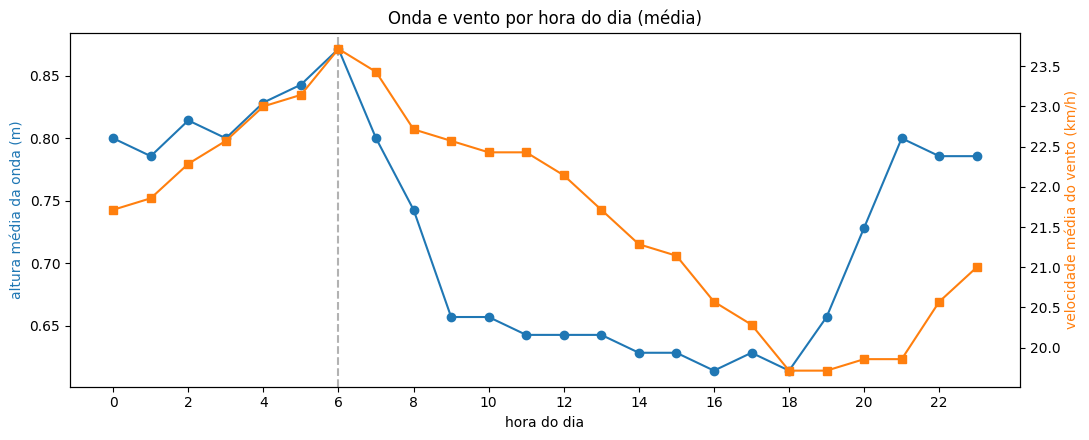

In [46]:
por_hora = dataset.groupby("hora")[["onda_altura_m", "vento_kmh"]].mean()

fig, ax1 = plt.subplots(figsize=(11, 4.5))

ax1.plot(por_hora.index, por_hora["onda_altura_m"], color="tab:blue", marker="o", label="onda (m)")
ax1.set_xlabel("hora do dia")
ax1.set_ylabel("altura média da onda (m)", color="tab:blue")
ax1.set_xticks(range(0, 24, 2))

ax2 = ax1.twinx()
ax2.plot(por_hora.index, por_hora["vento_kmh"], color="tab:orange", marker="s", label="vento (km/h)")
ax2.set_ylabel("velocidade média do vento (km/h)", color="tab:orange")

h_max = por_hora["onda_altura_m"].idxmax()
ax1.axvline(h_max, color="gray", linestyle="--", alpha=0.6)

plt.title("Onda e vento por hora do dia (média)")
fig.tight_layout()
plt.show()

- Existe relação visível entre a altura...?
= Enquanto a altura da maré segue regularmente, a altura da onda varia mais, com intervalos diferentes entre aumentos e diminuições. Fora isso, a altura da onda costuma seguir a altura da maré, com exceções.

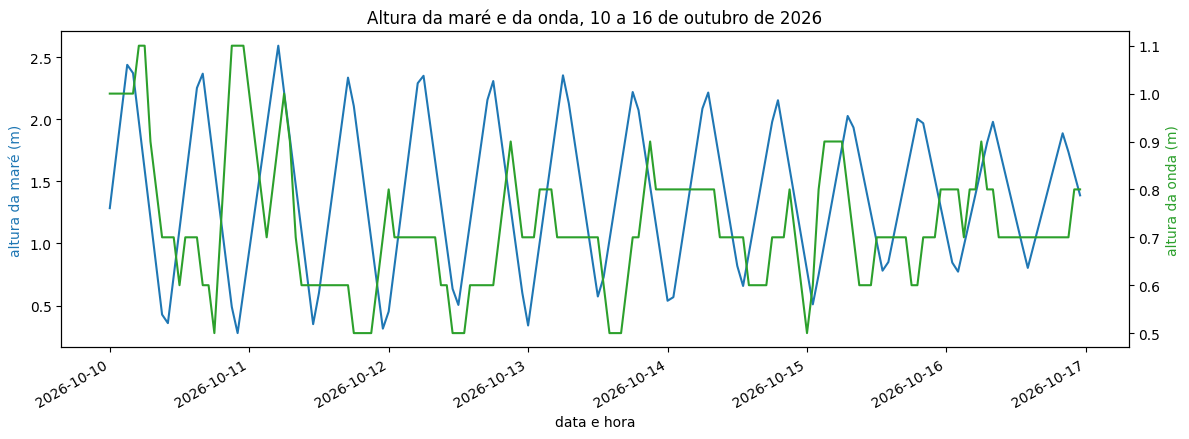

0.04996427467276856


In [ ]:
d = dataset.copy()
d["quando"] = d["data"] + pd.to_timedelta(d["hora"], unit="h")

fig, ax1 = plt.subplots(figsize=(12, 4.5))

ax1.plot(d["quando"], d["mare_m"], color="tab:blue", label="maré (m)")
ax1.set_xlabel("data e hora")
ax1.set_ylabel("altura da maré (m)", color="tab:blue")

ax2 = ax1.twinx()
ax2.plot(d["quando"], d["onda_altura_m"], color="tab:green", label="onda (m)")
ax2.set_ylabel("altura da onda (m)", color="tab:green")

plt.title("Altura da maré e da onda, 10 a 16 de outubro de 2026")
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

- Quais dias e horas da janela se destacam?
= Os dias alteram entre seus máximos e mínimos, os quais diminuem / aumentam em ciclos, enquanto as primeiras horas do dia (0h até 6h) têm alturas maiores, junto com as últimas horas do dia (20h até 23h).

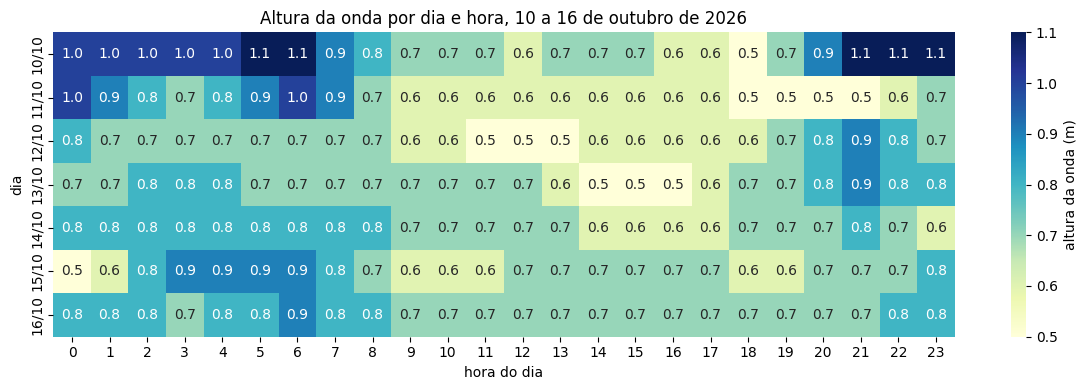

In [45]:
tabela = dataset.pivot(index="data", columns="hora", values="onda_altura_m")
tabela.index = tabela.index.strftime("%d/%m")

plt.figure(figsize=(12, 4))
sns.heatmap(tabela, cmap="YlGnBu", annot=True, fmt=".1f",
            cbar_kws={"label": "altura da onda (m)"})
plt.xlabel("hora do dia")
plt.ylabel("dia")
plt.title("Altura da onda por dia e hora, 10 a 16 de outubro de 2026")
plt.tight_layout()
plt.show()

## 6. Salvar o dataset processado

Grave o resultado em `../data/processed/dataset.csv`. A Etapa 3 lê esse
arquivo — se as colunas mudarem depois, o notebook de ML muda também.

In [34]:
dataset.to_csv("/home/laura/Documents/faculdade/trilha/TRILHA2026/miniprojeto2/data/processed/dataset.csv", index=False)

## 7. Conclusões

Em texto, sem código:

1. O que os dados mostram sobre as condições da janela coletada?
2. Que decisão de limpeza ou de junção você tomou que mais influencia o
   resultado, e por quê?
3. O que esses dados **não** permitem afirmar?

1. Que os dados mostram?
= Embora a janela seja curta, os dados mostram o padrão entre aumentos e diminuições de diferentes medidas relacionadas às marés (vento, tamanho de onda, tamanho da maré etc.), os quais, juntos, fazem uma visão geral da situação de surf pelo mês de outubro.

2. Que decisões mais influenciaram?
= A junção de horários não cruzados com a interpolação, a eliminação de linhas com informações nulas.

3. Que esses dados *não* permitem afirmar?
= Eles não permitem uma análise anual, já que somente há informações suficientes para a análise pertinente de um mês. 